In [14]:
# Block#1: Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix

print("Everything imported successfully!")

Everything imported successfully!


In [15]:
# Block#2: Load the dataset
df = pd.read_csv("house_prices.csv")

print("Shape:", df.shape)
df.head()

Shape: (21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [16]:
# Block 3 Find and Fix Missing Values

print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Fill number columns with median
for col in df.select_dtypes(include="number").columns:
    if df[col].isnull().any():
        df[col].fillna(df[col].median(), inplace=True)

# Fill text columns with most common value
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col].fillna(df[col].mode()[0], inplace=True)

print("\nMissing values after cleaning:", df.isnull().sum().sum())

Missing values before cleaning:
Series([], dtype: int64)

Missing values after cleaning: 0


In [17]:
# Block 4 Remove Outliers

def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    return data[(data[column] >= lower_limit) & (data[column] <= upper_limit)]

rows_before = len(df)

# Using YOUR actual column names
df = remove_outliers(df, "sqft_living")  # remove extreme house sizes
df = remove_outliers(df, "price")        # remove extreme prices

df.reset_index(drop=True, inplace=True)

print(f"Rows removed  : {rows_before - len(df)}")
print(f"Rows remaining: {len(df)}")

Rows removed  : 1410
Rows remaining: 20203


In [18]:
#Block 5 — Encode Text Columns

# The 'date' column is text so we convert it to a number
# We extract just the year from the date

df["date"] = pd.to_datetime(df["date"]).dt.year

print("Date column converted to year successfully!")
print(df["date"].head())

Date column converted to year successfully!
0    2014
1    2014
2    2015
3    2014
4    2015
Name: date, dtype: int32


In [19]:
# Block 6 — Create New Features

# Feature 1: Age of the house (yr_built is your column name)
df["HouseAge"] = 2015 - df["yr_built"]

# Feature 2: Was the house ever renovated? 1 = yes, 0 = no
df["Renovated"] = (df["yr_renovated"] > 0).astype(int)

# Feature 3: Total area including basement
df["TotalArea"] = df["sqft_living"] + df["sqft_basement"]

# Feature 4: Living area quality score (grade x living area)
df["QualityArea"] = df["grade"] * df["sqft_living"]

print("4 new features created successfully!")
print(df[["HouseAge", "Renovated", "TotalArea", "QualityArea"]].head())

4 new features created successfully!
   HouseAge  Renovated  TotalArea  QualityArea
0        60          0       1180         8260
1        64          1       2970        17990
2        82          0        770         4620
3        50          0       2870        13720
4        28          0       1680        13440


In [20]:
# Block 7 — Prepare Data for Training

# Turn price into 3 categories: 0 = Low, 1 = Mid, 2 = High
df["PriceClass"] = pd.qcut(df["price"], q=3, labels=[0, 1, 2]).astype(int)

# These are YOUR actual column names
features = [
    "bedrooms", "bathrooms", "sqft_living", "sqft_lot",
    "floors", "waterfront", "view", "condition", "grade",
    "sqft_above", "sqft_basement", "yr_built", "yr_renovated",
    "zipcode", "lat", "long", "sqft_living15", "sqft_lot15",
    "HouseAge", "Renovated", "TotalArea", "QualityArea"
]

X = df[features]    # input columns
y = df["PriceClass"] # what we want to predict

# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training samples : {len(X_train)}")
print(f"Testing samples  : {len(X_test)}")

Training samples : 16162
Testing samples  : 4041


In [21]:
# Block 8 — Model 1: Linear Regression

# Scale the data first — required for Linear Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Round predictions to 0, 1, or 2
lr_pred = lr_model.predict(X_test_scaled).round().clip(0, 2).astype(int)

print("--- Linear Regression Results ---")
print("Accuracy :", round(accuracy_score(y_test, lr_pred), 4))
print("Precision:", round(precision_score(y_test, lr_pred, average="weighted", zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, lr_pred, average="weighted"), 4))

--- Linear Regression Results ---
Accuracy : 0.6639
Precision: 0.7476
F1-Score : 0.6715


In [22]:
# Block 9 — Model 2: Decision Tree

dt_model = DecisionTreeClassifier(max_depth=6, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("--- Decision Tree Results ---")
print("Accuracy :", round(accuracy_score(y_test, dt_pred), 4))
print("Precision:", round(precision_score(y_test, dt_pred, average="weighted", zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, dt_pred, average="weighted"), 4))

--- Decision Tree Results ---
Accuracy : 0.7545
Precision: 0.764
F1-Score : 0.7577


In [23]:
# Block 10 — Model 3: Random Forest

rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("--- Random Forest Results ---")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, average="weighted", zero_division=0), 4))
print("F1-Score :", round(f1_score(y_test, rf_pred, average="weighted"), 4))

--- Random Forest Results ---
Accuracy : 0.7837
Precision: 0.7881
F1-Score : 0.7854


In [24]:
# Block 11 — Compare All 3 Models

summary = []

for name, pred in [("Linear Regression", lr_pred),
                    ("Decision Tree",     dt_pred),
                    ("Random Forest",     rf_pred)]:
    summary.append({
        "Model"    : name,
        "Accuracy" : round(accuracy_score(y_test, pred), 4),
        "Precision": round(precision_score(y_test, pred, average="weighted", zero_division=0), 4),
        "Recall"   : round(recall_score(y_test, pred, average="weighted", zero_division=0), 4),
        "F1-Score" : round(f1_score(y_test, pred, average="weighted"), 4),
    })

summary_df = pd.DataFrame(summary)
print(summary_df.to_string(index=False))

            Model  Accuracy  Precision  Recall  F1-Score
Linear Regression    0.6639     0.7476  0.6639    0.6715
    Decision Tree    0.7545     0.7640  0.7545    0.7577
    Random Forest    0.7837     0.7881  0.7837    0.7854


In [25]:
# Block 12 — Cross Validation

print("5-Fold Cross Validation Results:\n")

for model, name in [(dt_model, "Decision Tree"),
                     (rf_model, "Random Forest")]:

    scores = cross_val_score(model, X, y, cv=5, scoring="f1_weighted")

    print(f"{name}")
    print(f"  Scores in each fold : {scores.round(4)}")
    print(f"  Average score       : {scores.mean():.4f}")
    print(f"  Standard deviation  : {scores.std():.4f}\n")

5-Fold Cross Validation Results:

Decision Tree
  Scores in each fold : [0.7715 0.7572 0.7635 0.7747 0.7513]
  Average score       : 0.7636
  Standard deviation  : 0.0087

Random Forest
  Scores in each fold : [0.7872 0.7895 0.7941 0.7985 0.7955]
  Average score       : 0.7929
  Standard deviation  : 0.0041



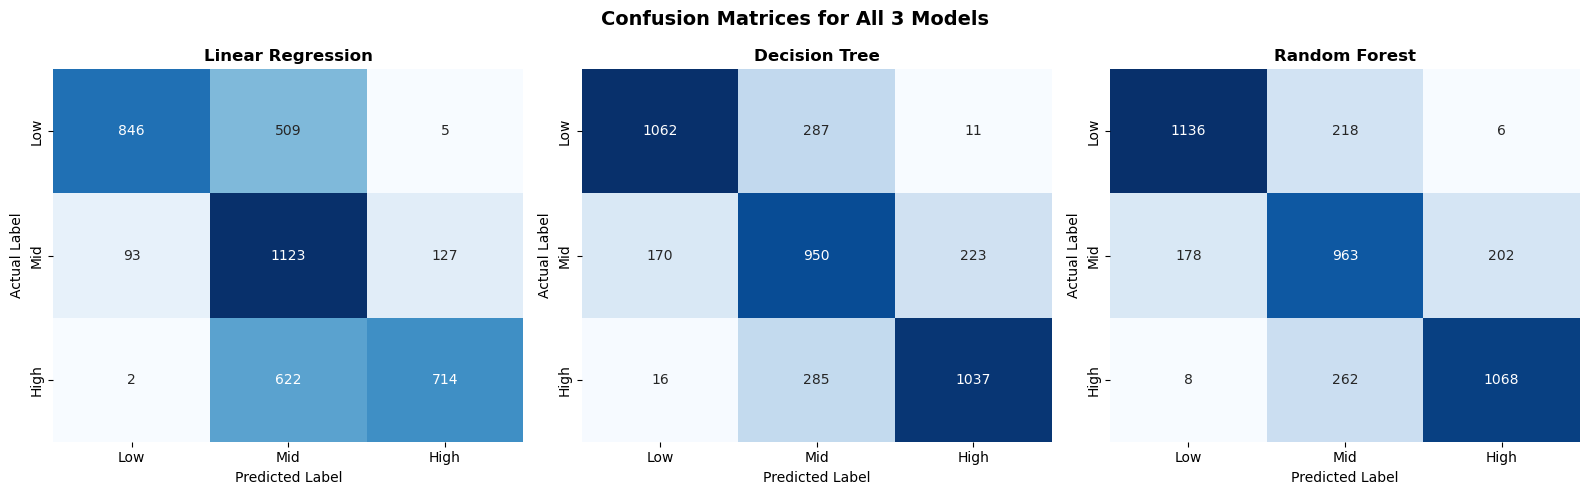

In [26]:
# Block 13 — Plot: Confusion Matrices

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Confusion Matrices for All 3 Models", fontsize=14, fontweight="bold")

class_labels = ["Low", "Mid", "High"]

for ax, (name, pred) in zip(axes, [("Linear Regression", lr_pred),
                                     ("Decision Tree",     dt_pred),
                                     ("Random Forest",     rf_pred)]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_labels,
                yticklabels=class_labels,
                ax=ax, cbar=False)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

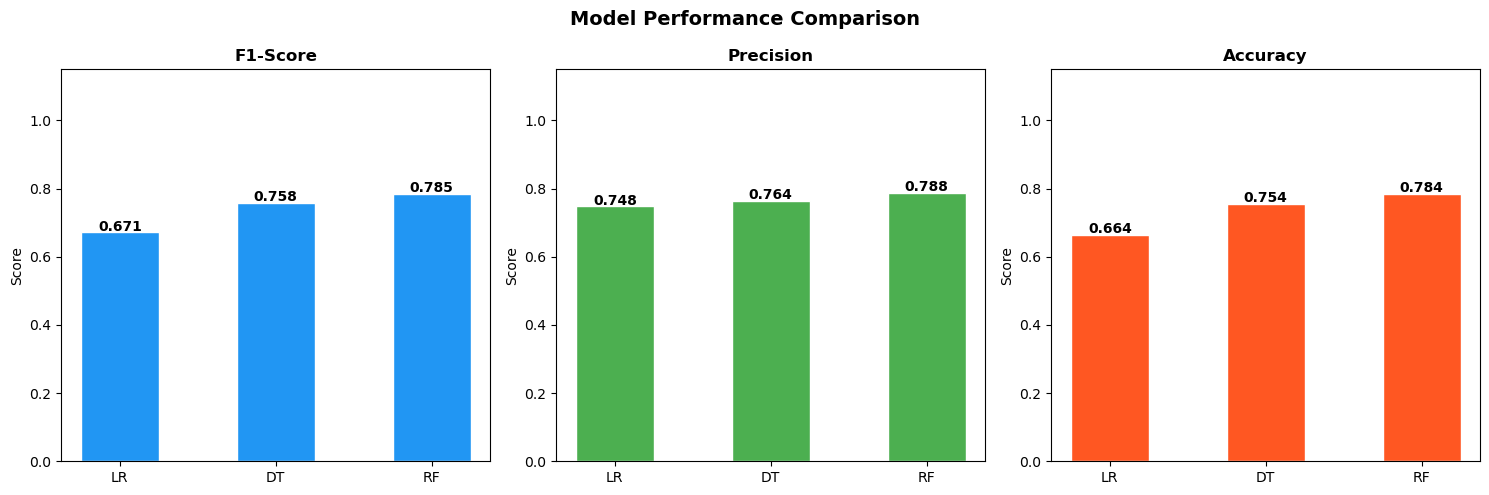

In [27]:
# Block 14 — Plot: Bar Chart Comparison

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Model Performance Comparison", fontsize=14, fontweight="bold")

for ax, metric, color in zip(
    axes,
    ["F1-Score", "Precision", "Accuracy"],
    ["#2196F3",  "#4CAF50",   "#FF5722"]
):
    values = summary_df[metric].tolist()
    bars = ax.bar(["LR", "DT", "RF"], values, color=color, edgecolor="white", width=0.5)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{v:.3f}", ha="center", fontsize=10, fontweight="bold")
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

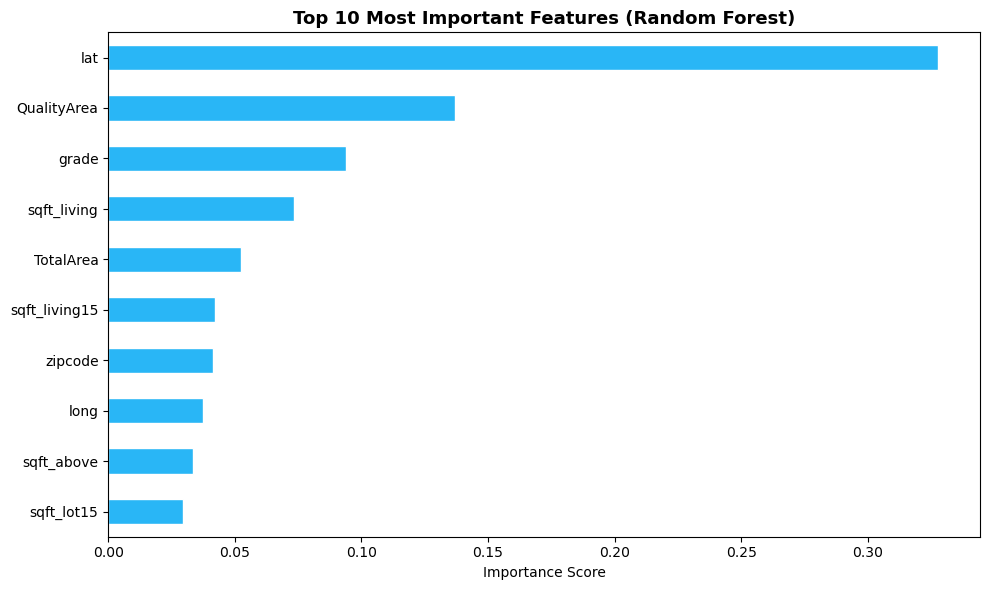

In [28]:
# Block 15 — Plot: Feature Importance

importance_scores = pd.Series(rf_model.feature_importances_, index=features)
top_10 = importance_scores.sort_values().tail(10)

plt.figure(figsize=(10, 6))
top_10.plot(kind="barh", color="#29B6F6", edgecolor="white")
plt.title("Top 10 Most Important Features (Random Forest)", fontsize=13, fontweight="bold")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

In [29]:
#Block 16 — Final Verdict


best_model = summary_df.loc[summary_df["F1-Score"].idxmax()]

print("=" * 45)
print("         FINAL VERDICT")
print("=" * 45)
print(f"Best Model  : {best_model['Model']}")
print(f"F1-Score    : {best_model['F1-Score']}")
print(f"Precision   : {best_model['Precision']}")
print(f"Accuracy    : {best_model['Accuracy']}")

print("""
Why is Random Forest the best model?

1. It builds 100 trees instead of just 1,
   so it makes smarter and more stable predictions.

2. It works well with location data like lat and long
   which are very important in house pricing.

3. It does not overfit like a single Decision Tree.

4. Cross-validation proved it performs consistently
   on data it has never seen before.

5. Linear Regression is too simple for this data
   because price depends on many complex factors.

Conclusion: Random Forest is our best model!
""")

         FINAL VERDICT
Best Model  : Random Forest
F1-Score    : 0.7854
Precision   : 0.7881
Accuracy    : 0.7837

Why is Random Forest the best model?

1. It builds 100 trees instead of just 1,
   so it makes smarter and more stable predictions.

2. It works well with location data like lat and long
   which are very important in house pricing.

3. It does not overfit like a single Decision Tree.

4. Cross-validation proved it performs consistently
   on data it has never seen before.

5. Linear Regression is too simple for this data
   because price depends on many complex factors.

Conclusion: Random Forest is our best model!

